# lab 4: ddpm de la zero pe fashion-mnist

scopul lucrării: să facem un model de difuzie ddpm care desenează haine noi.

ideea este simplă:

* **procesul direct** strică o imagine pas cu pas, adăugând zgomot
* **rețeaua** învață să ghicească zgomotul care a fost adăugat
* **generarea** pornește de la zgomot pur și scoate zgomotul pas cu pas, până apare o imagine

avem T = 1000 de pași, numerotați de la 0 la 999.

In [1]:
import math, time
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

torch.manual_seed(42)
device = "cuda" if torch.cuda.is_available() else "cpu"
T = 1000
print(device)

cuda


## sarcina 1. datele

încărcăm fashion-mnist. imaginile au 28×28 pixeli. adăugăm 2 pixeli pe fiecare margine și ajungem la 32×32.

aducem pixelii în intervalul de la minus 1 la 1. zgomotul gaussian are și el valori în jurul lui 0, așa că se potrivesc.

In [2]:
tf = transforms.Compose([
    transforms.Pad(2),                     # 28x28 -> 32x32
    transforms.ToTensor(),                 # [0, 1]
    transforms.Normalize((0.5,), (0.5,)),  # [-1, 1]
])
data = datasets.FashionMNIST("data", train=True, download=True, transform=tf)
loader = DataLoader(data, batch_size=128, shuffle=True, drop_last=True)

x, _ = next(iter(loader))
print(x.shape, x.min().item(), x.max().item())

torch.Size([128, 1, 32, 32]) -1.0 1.0


facem o funcție mică care arată mai multe imagini într-o grilă. o vom folosi des.

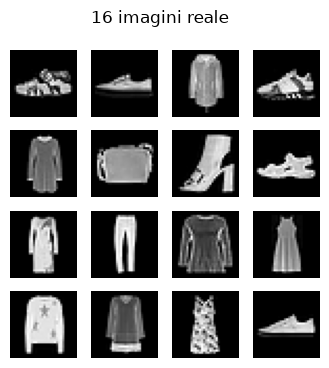

In [3]:
def show_grid(x, nrow, title=""):
    x = (x.detach().cpu().clamp(-1, 1) + 1) / 2   # back to [0, 1]
    n = x.shape[0]
    ncol = math.ceil(n / nrow)
    plt.figure(figsize=(ncol, nrow))
    for i in range(n):
        plt.subplot(nrow, ncol, i + 1)
        plt.imshow(x[i, 0], cmap="gray")
        plt.axis("off")
    plt.suptitle(title)
    plt.show()

show_grid(x[:16], 4, "16 imagini reale")

## sarcina 2. procesul direct

un program de zgomot spune cât zgomot adăugăm la fiecare pas. îl notăm cu β.

**programul liniar**: β crește uniform de la 0.0001 la 0.02.

In [4]:
def make_schedule(beta):
    alpha = 1 - beta
    ab = torch.cumprod(alpha, dim=0)   # alpha bar = a1 * a2 * ... * at
    return {"beta": beta.to(device), "alpha": alpha.to(device), "ab": ab.to(device)}

lin = make_schedule(torch.linspace(1e-4, 0.02, T))
print(lin["ab"][:3], lin["ab"][-1])

tensor([0.9999, 0.9998, 0.9996], device='cuda:0') tensor(4.0358e-05, device='cuda:0')


**programul cosinus**: aici pornim direct de la ᾱ, care scade ca o curbă cosinus. apoi scoatem β din ᾱ.

In [5]:
def cosine_beta(T, s=0.008):
    t = torch.arange(T + 1, dtype=torch.float64)
    f = torch.cos(((t / T + s) / (1 + s)) * math.pi / 2) ** 2
    ab = f / f[0]
    beta = 1 - ab[1:] / ab[:-1]
    return beta.clamp(max=0.999).float()

cos = make_schedule(cosine_beta(T))
print(cos["ab"][:3], cos["ab"][-1])

tensor([1.0000, 0.9999, 0.9999], device='cuda:0') tensor(2.4287e-09, device='cuda:0')


funcția `q_sample` sare direct la pasul t, fără să treacă prin pașii de dinainte:

xₜ = √ᾱₜ · x₀ + √(1 − ᾱₜ) · ε

In [6]:
def q_sample(x0, t, eps, s=lin):
    ab = s["ab"][t].view(-1, 1, 1, 1)
    return ab.sqrt() * x0 + (1 - ab).sqrt() * eps

luăm aceeași imagine și același zgomot. o stricăm la mai mulți pași, cu ambele programe.

primul rând este programul liniar, al doilea este cosinus.

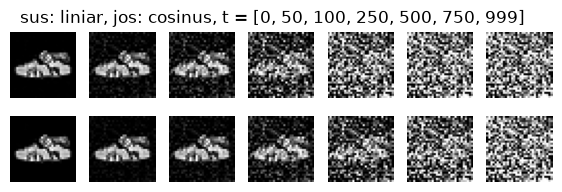

In [7]:
steps = [0, 50, 100, 250, 500, 750, 999]
x0 = x[:1].to(device)
eps = torch.randn_like(x0)

rows = []
for s in [lin, cos]:
    for t in steps:
        rows.append(q_sample(x0, torch.tensor([t], device=device), eps, s))
show_grid(torch.cat(rows), 2, "sus: liniar, jos: cosinus, t = " + str(steps))

acum desenăm √ᾱₜ. această valoare spune cât a mai rămas din imaginea inițială la pasul t.

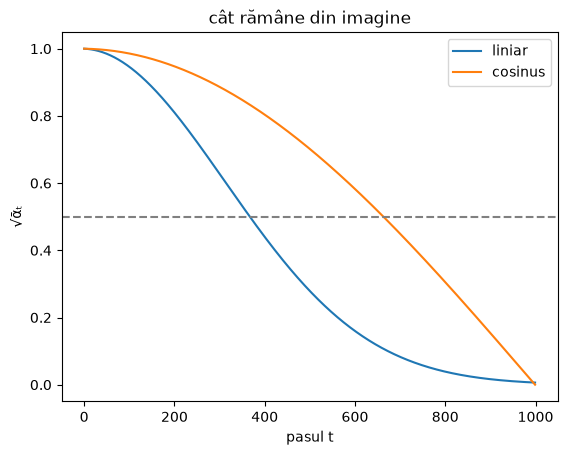

In [8]:
plt.plot(lin["ab"].sqrt().cpu(), label="liniar")
plt.plot(cos["ab"].sqrt().cpu(), label="cosinus")
plt.axhline(0.5, color="gray", ls="--")
plt.xlabel("pasul t")
plt.ylabel("√ᾱₜ")
plt.title("cât rămâne din imagine")
plt.legend()
plt.show()

In [9]:
for name, s in [("liniar", lin), ("cosinus", cos)]:
    t_half = (s["ab"].sqrt() < 0.5).nonzero()[0].item()
    print(name, ": √ᾱₜ scade sub 0.5 la pasul", t_half)

liniar : √ᾱₜ scade sub 0.5 la pasul 368
cosinus : √ᾱₜ scade sub 0.5 la pasul 664


observație: la programul liniar imaginea dispare repede, deja pe la jumătate e aproape doar zgomot. la cosinus imaginea se pierde mai încet și mai uniform.

## sarcina 3. rețeaua

rețeaua este un u-net mic. ea primește imaginea zgomotoasă și pasul t, și dă zgomotul prezis.

în comentarii am marcat:

* **[t]** unde intră pasul t
* **[skip]** conexiunile skip (lipim ieșirea din coborâre cu cea din urcare)
* **[rezidual]** conexiunile reziduale (adunăm intrarea blocului la ieșire)

In [10]:
def time_embedding(t, dim=128):
    # t: tensor (B,) with steps; returns (B, dim)
    half = dim // 2
    freqs = torch.exp(-math.log(10000) * torch.arange(half, device=t.device) / half)
    args = t.float()[:, None] * freqs[None, :]
    return torch.cat([torch.sin(args), torch.cos(args)], dim=1)

class ResBlock(nn.Module):
    def __init__(self, c_in, c_out, t_dim=128):
        super().__init__()
        self.norm1 = nn.GroupNorm(8, c_in)
        self.conv1 = nn.Conv2d(c_in, c_out, 3, padding=1)
        self.t_proj = nn.Linear(t_dim, c_out)          # [t] step t enters here
        self.norm2 = nn.GroupNorm(8, c_out)
        self.conv2 = nn.Conv2d(c_out, c_out, 3, padding=1)
        self.skip = nn.Conv2d(c_in, c_out, 1) if c_in != c_out else nn.Identity()

    def forward(self, x, temb):
        h = self.conv1(F.silu(self.norm1(x)))
        h = h + self.t_proj(temb)[:, :, None, None]    # [t] add step info to every pixel
        h = self.conv2(F.silu(self.norm2(h)))
        return h + self.skip(x)                        # [rezidual] residual connection

class UNet(nn.Module):
    def __init__(self, ch=(32, 64, 128), t_dim=128):
        super().__init__()
        self.t_mlp = nn.Sequential(nn.Linear(t_dim, t_dim), nn.SiLU(), nn.Linear(t_dim, t_dim))
        self.inp = nn.Conv2d(1, ch[0], 3, padding=1)
        self.down1 = ResBlock(ch[0], ch[0])
        self.down2 = ResBlock(ch[0], ch[1])
        self.down3 = ResBlock(ch[1], ch[2])
        self.mid = ResBlock(ch[2], ch[2])
        self.up3 = ResBlock(2 * ch[2], ch[1])
        self.up2 = ResBlock(2 * ch[1], ch[0])
        self.up1 = ResBlock(2 * ch[0], ch[0])
        self.out = nn.Conv2d(ch[0], 1, 1)

    def forward(self, x, t):
        temb = self.t_mlp(time_embedding(t))           # [t] step t -> vector
        x = self.inp(x)
        s1 = self.down1(x, temb)                       # 32x32
        s2 = self.down2(F.avg_pool2d(s1, 2), temb)     # 16x16
        s3 = self.down3(F.avg_pool2d(s2, 2), temb)     # 8x8
        h = self.mid(F.avg_pool2d(s3, 2), temb)        # 4x4
        up = lambda z: F.interpolate(z, scale_factor=2)
        h = self.up3(torch.cat([up(h), s3], dim=1), temb)   # [skip] concat with s3
        h = self.up2(torch.cat([up(h), s2], dim=1), temb)   # [skip] concat with s2
        h = self.up1(torch.cat([up(h), s1], dim=1), temb)   # [skip] concat with s1
        return self.out(h)                             # predicted noise

verificăm că ieșirea are aceeași formă ca intrarea și numărăm parametrii.

In [11]:
out = UNet()(torch.randn(8, 1, 32, 32), torch.randint(0, 1000, (8,)))
print("forma ieșirii:", out.shape)

def n_params(m):
    return sum(p.numel() for p in m.parameters())

print("parametri:", n_params(UNet()))

forma ieșirii: torch.Size([8, 1, 32, 32])
parametri: 979585


## sarcina 4. antrenarea cu programul liniar

la fiecare lot:

1. alegem un pas t aleator
2. facem un zgomot ε
3. stricăm imaginea cu `q_sample`
4. rețeaua ghicește ε, iar pierderea este eroarea pătratică medie

facem o funcție de antrenare, ca să o folosim și pentru programul cosinus.

după antrenare salvăm modelul și pierderile într-un fișier. dacă sesiunea se închide, la a doua rulare încărcăm fișierul și nu mai antrenăm din nou.

In [12]:
import os

def train_or_load(path, s, ch=(32, 64, 128)):
    if os.path.exists(path):
        ck = torch.load(path)
        model = UNet(ch).to(device)
        model.load_state_dict(ck["state"])
        print("încărcat din", path)
        return model, ck["losses"], ck["minutes"]
    model, losses, minutes = train(s, ch)
    torch.save({"state": model.state_dict(), "losses": losses, "minutes": minutes}, path)
    return model, losses, minutes

def train(s, ch=(32, 64, 128), epochs=15):
    torch.manual_seed(42)
    model = UNet(ch).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=2e-4)
    losses = []
    start = time.perf_counter()
    for ep in range(epochs):
        model.train()
        total = 0
        for x0, _ in loader:
            x0 = x0.to(device)
            t = torch.randint(0, T, (x0.shape[0],), device=device)
            eps = torch.randn_like(x0)
            loss = F.mse_loss(model(q_sample(x0, t, eps, s), t), eps)
            opt.zero_grad()
            loss.backward()
            opt.step()
            total += loss.item()
        losses.append(total / len(loader))
        print(f"epoca {ep + 1}: pierdere {losses[-1]:.4f}")
    minutes = (time.perf_counter() - start) / 60
    print(f"timp de antrenare: {minutes:.1f} min")
    return model, losses, minutes

In [13]:
model_lin, loss_lin, time_lin = train_or_load("ddpm_linear.pt", lin)

încărcat din ddpm_linear.pt


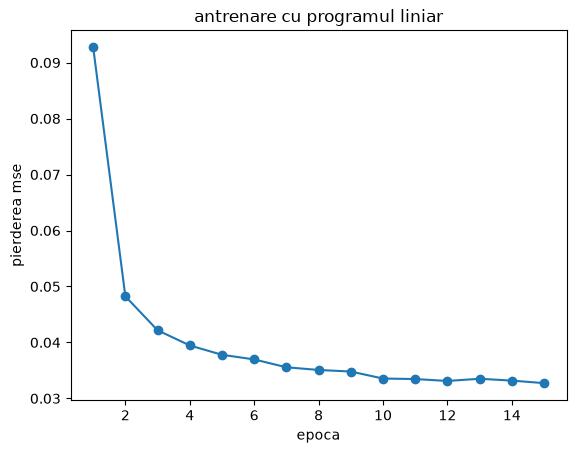

In [14]:
plt.plot(range(1, 16), loss_lin, marker="o")
plt.xlabel("epoca")
plt.ylabel("pierderea mse")
plt.title("antrenare cu programul liniar")
plt.show()

## sarcina 5. generarea ddpm

pornim de la zgomot pur și mergem înapoi de la t = 999 la t = 0. la fiecare pas scoatem puțin din zgomotul prezis și adăugăm puțin zgomot nou.

la ultimul pas nu mai adăugăm zgomot.

In [15]:
@torch.no_grad()
def ddpm_sample(model, s, x):
    model.eval()
    keep = set(torch.linspace(T - 1, 0, 8).long().tolist())   # 8 moments to save
    states = []
    for t in range(T - 1, -1, -1):
        tt = torch.full((x.shape[0],), t, device=device)
        eps = model(x, tt)
        b, a, ab = s["beta"][t], s["alpha"][t], s["ab"][t]
        x = (x - b / (1 - ab).sqrt() * eps) / a.sqrt()
        if t > 0:
            x = x + b.sqrt() * torch.randn_like(x)              # sigma^2 = beta
        if t in keep:
            states.append(x[:1].clone())
    return x.clamp(-1, 1), torch.cat(states)

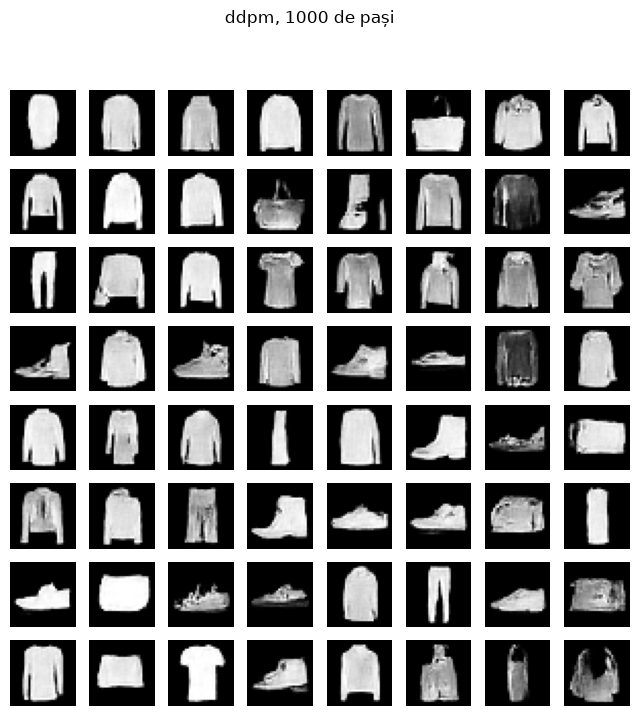

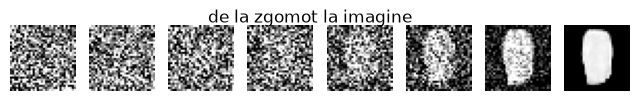

In [16]:
torch.manual_seed(42)
noise = torch.randn(64, 1, 32, 32, device=device)   # same start noise for all methods

imgs, states = ddpm_sample(model_lin, lin, noise.clone())
show_grid(imgs, 8, "ddpm, 1000 de pași")
show_grid(states, 1, "de la zgomot la imagine")

## sarcina 6. mai puțini pași cu ddim

ddim este determinist: nu adaugă zgomot nou. la fiecare pas:

1. ghicim imaginea curată x̂₀
2. sărim direct la pasul următor din listă

așa putem folosi doar 10 sau 20 de pași în loc de 1000.

la pașii mari ᾱₜ este foarte mic (la cosinus, la t = 999, ᾱₜ ≈ 0.000000002). când împărțim la √ᾱₜ, orice mică greșeală a rețelei devine uriașă. de aceea tăiem x̂₀ în intervalul de la minus 1 la 1, unde stau pixelii adevărați. fără asta, modelul cosinus dă doar pete albe și negre.

In [17]:
@torch.no_grad()
def ddim_sample(model, s, x, n):
    model.eval()
    ts = torch.linspace(T - 1, 0, n).long().tolist()
    for i, t in enumerate(ts):
        tt = torch.full((x.shape[0],), t, device=device)
        eps = model(x, tt)
        ab = s["ab"][t]
        x0 = (x - (1 - ab).sqrt() * eps) / ab.sqrt()    # guess of the clean image
        x0 = x0.clamp(-1, 1)                            # pixels must stay in [-1, 1]
        if i == len(ts) - 1:
            x = x0
        else:
            ab2 = s["ab"][ts[i + 1]]
            x = ab2.sqrt() * x0 + (1 - ab2).sqrt() * eps
    return x.clamp(-1, 1)

măsurăm timpul pentru 64 de imagini. înainte de fiecare citire a ceasului așteptăm ca gpu să termine.

In [18]:
def sync():
    if device == "cuda":
        torch.cuda.synchronize()

def timed(fn):
    sync()
    start = time.perf_counter()
    out = fn()
    sync()
    return out, time.perf_counter() - start

results = {}
(img_ddpm, _), sec = timed(lambda: ddpm_sample(model_lin, lin, noise.clone()))
results["DDPM 1000"] = (img_ddpm, sec)
for n in [1000, 200, 50, 20, 10]:
    img, sec = timed(lambda: ddim_sample(model_lin, lin, noise.clone(), n))
    results[f"DDIM {n}"] = (img, sec)

for name, (img, sec) in results.items():
    print(f"{name}: {sec:.2f} s pentru 64 de imagini")

DDPM 1000: 11.44 s pentru 64 de imagini
DDIM 1000: 11.42 s pentru 64 de imagini
DDIM 200: 2.30 s pentru 64 de imagini
DDIM 50: 0.57 s pentru 64 de imagini
DDIM 20: 0.23 s pentru 64 de imagini
DDIM 10: 0.12 s pentru 64 de imagini


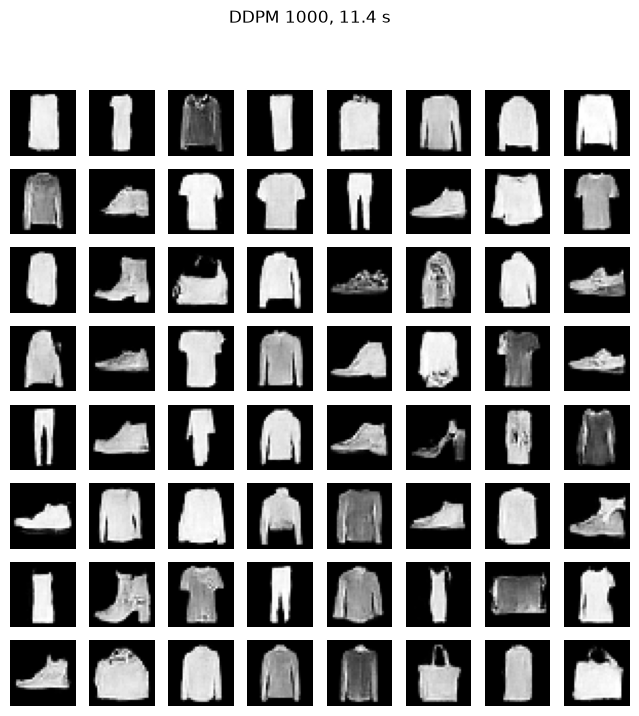

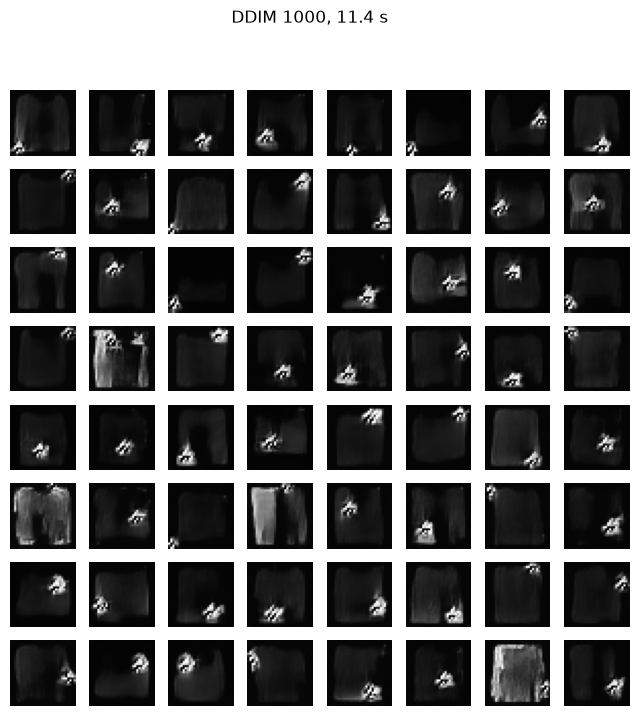

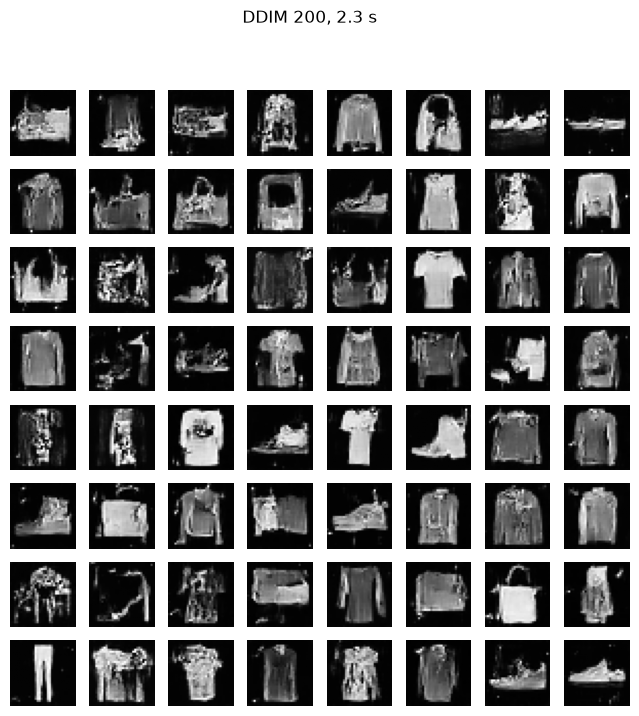

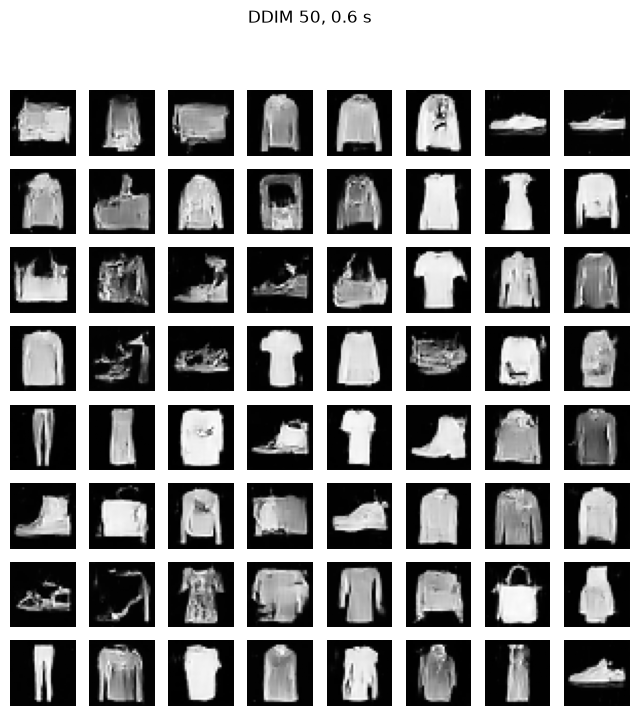

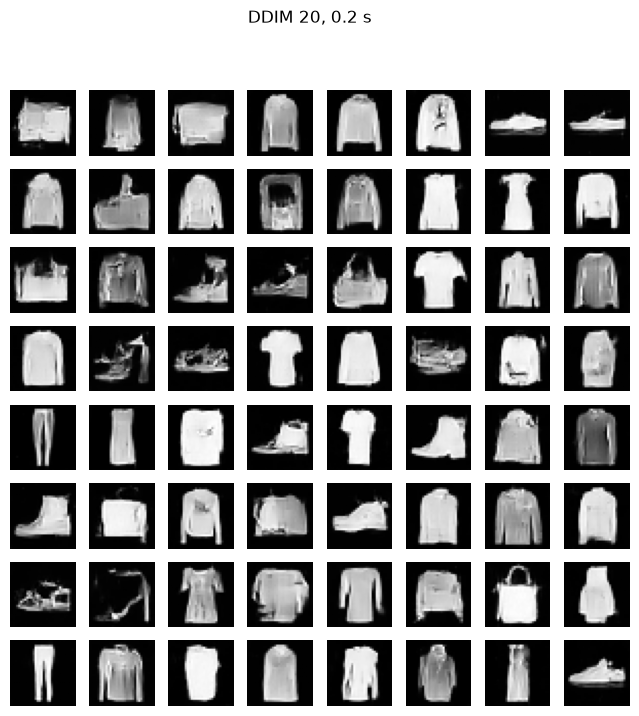

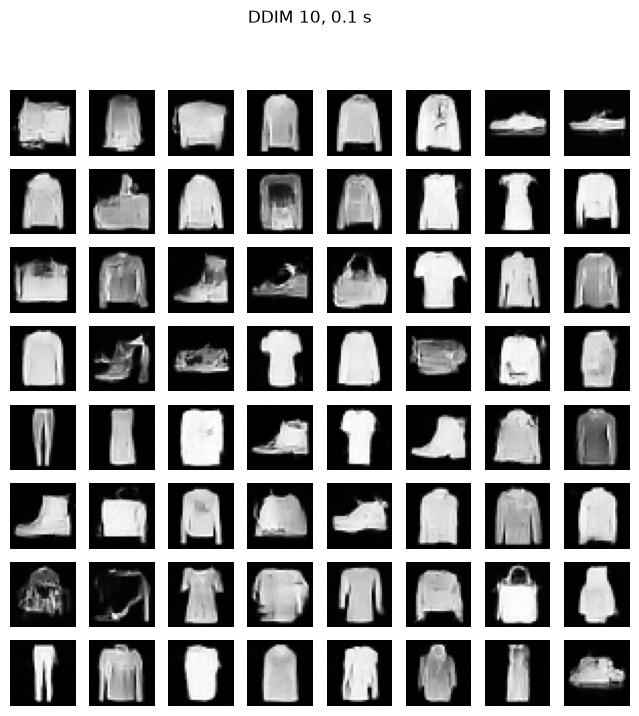

In [19]:
for name, (img, sec) in results.items():
    show_grid(img, 8, f"{name}, {sec:.1f} s")

rezultatele mele (notele 1 până la 5 le-am dat uitându-mă la grile):

* DDPM 1000: 11.4 s, nota 4. haine clare și variate, puțin zgomot pe margini
* DDIM 1000: 11.4 s, nota 4. la fel de bune ca ddpm, dar alte imagini, pentru că ddim nu adaugă zgomot nou
* DDIM 200: 2.3 s, nota 4. aproape identice cu ddim 1000
* DDIM 50: 0.6 s, nota 4. încă aproape identice cu ddim 1000
* DDIM 20: 0.2 s, nota 4. aceleași haine, detaliile mici încep să se piardă
* DDIM 10: 0.1 s, nota 3. formele sunt bune, dar imaginile sunt mai neclare, iar câteva obiecte sunt stricate

## sarcina 7. liniar vs. cosinus

antrenăm același model, cu aceleași setări, dar cu programul cosinus.

In [20]:
model_cos, loss_cos, time_cos = train_or_load("ddpm_cosine.pt", cos)

încărcat din ddpm_cosine.pt


generăm cu ddim la 50 și la 20 de pași, din același zgomot, cu ambele modele.

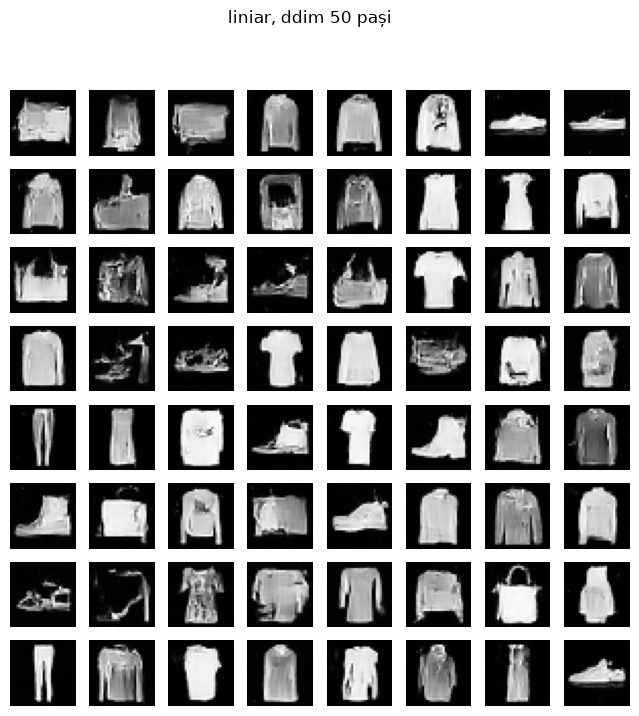

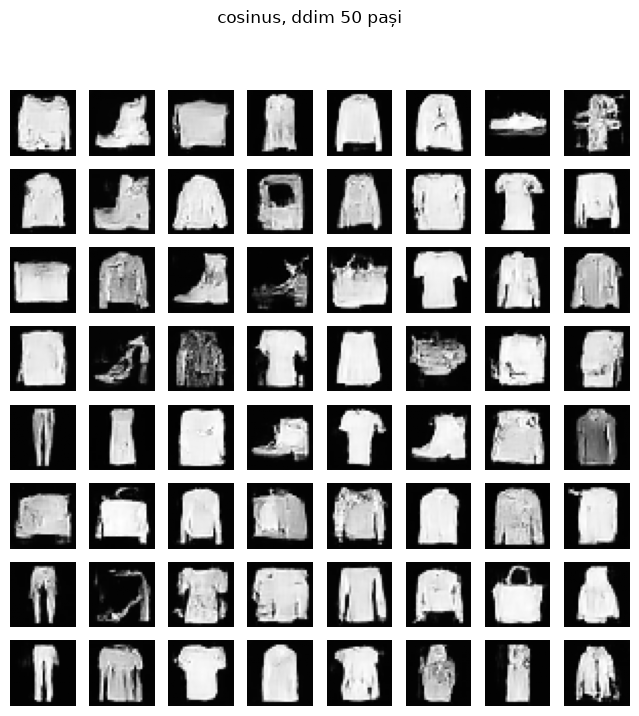

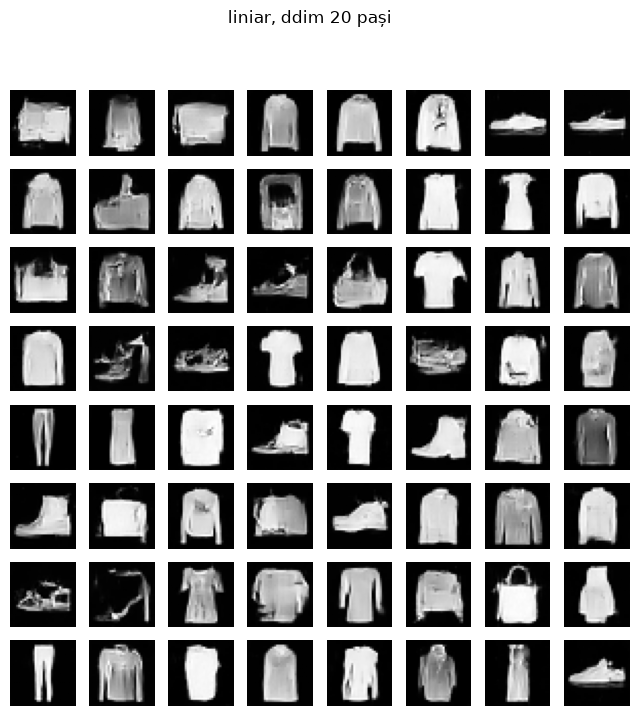

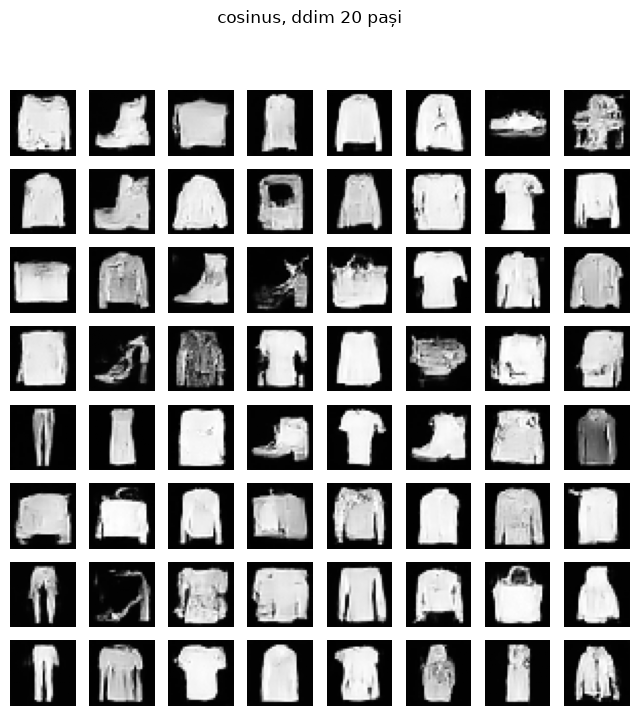

In [21]:
for n in [50, 20]:
    a = ddim_sample(model_lin, lin, noise.clone(), n)
    b = ddim_sample(model_cos, cos, noise.clone(), n)
    show_grid(a, 8, f"liniar, ddim {n} pași")
    show_grid(b, 8, f"cosinus, ddim {n} pași")

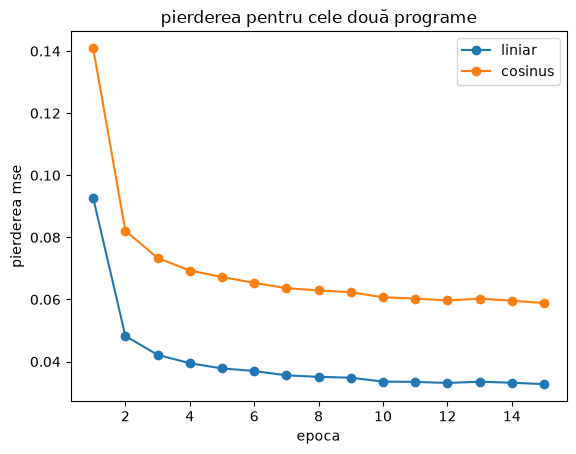

In [22]:
plt.plot(range(1, 16), loss_lin, marker="o", label="liniar")
plt.plot(range(1, 16), loss_cos, marker="o", label="cosinus")
plt.xlabel("epoca")
plt.ylabel("pierderea mse")
plt.title("pierderea pentru cele două programe")
plt.legend()
plt.show()

notele mele:

* liniar, ddim 50: nota 4. imagini curate și netede
* liniar, ddim 20: nota 4. aproape la fel ca la 50
* cosinus, ddim 50: nota 3. se văd mai multe detalii (texturi, cusături), dar imaginile sunt prea albe și au mai multe pete
* cosinus, ddim 20: nota 3. aproape la fel ca la 50 de pași

în experimentul meu, după doar 15 epoci, modelul liniar a dat imagini puțin mai curate. ambele modele merg bine la 20 de pași, deci ddim funcționează pentru amândouă.

atenție: pierderile nu se pot compara direct. fiecare program pune alte niveluri de zgomot, deci media se face pe lucruri diferite. comparăm modelele după imagini.

## bonus. o rețea mai mică

antrenăm `UNet(ch=(16, 32, 64))` cu programul liniar și o comparăm cu cea mare.

încărcat din ddpm_small.pt
parametri mare: 979585  mic: 286145
timp mare: 9.5 min  mic: 9.9 min


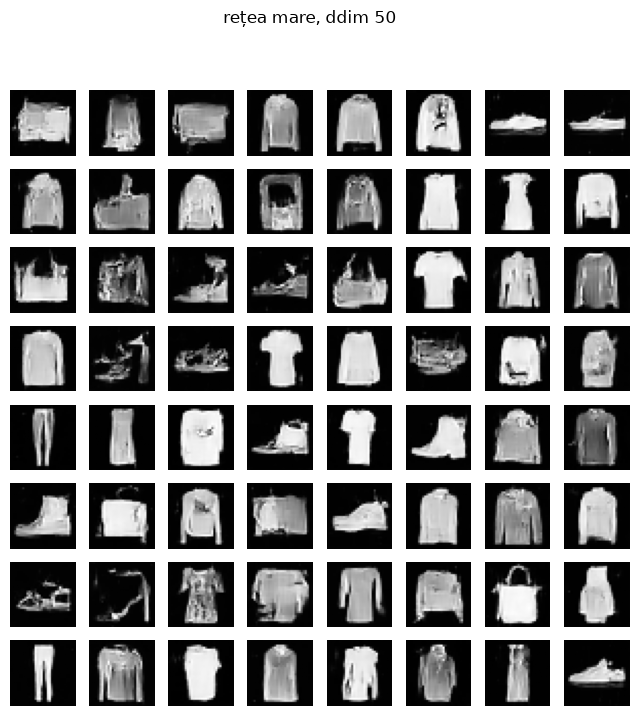

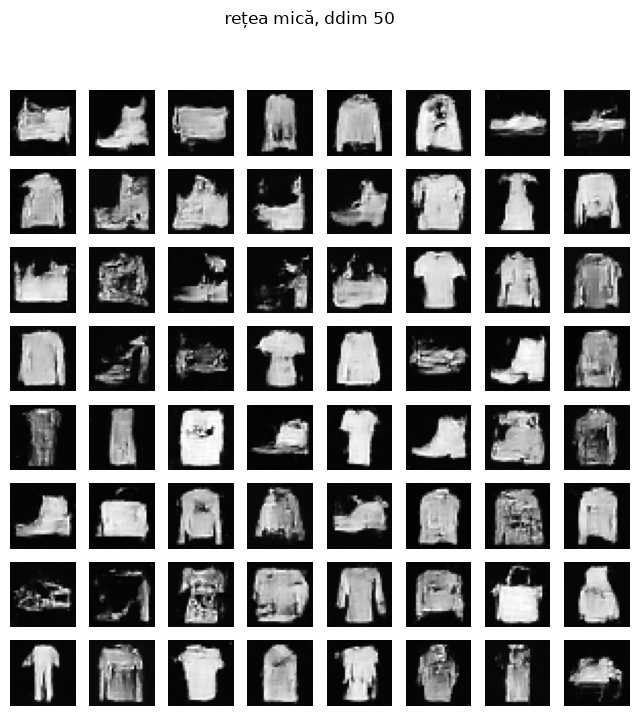

In [23]:
model_small, loss_small, time_small = train_or_load("ddpm_small.pt", lin, ch=(16, 32, 64))

print("parametri mare:", n_params(model_lin), " mic:", n_params(model_small))
print(f"timp mare: {time_lin:.1f} min  mic: {time_small:.1f} min")

show_grid(ddim_sample(model_lin, lin, noise.clone(), 50), 8, "rețea mare, ddim 50")
show_grid(ddim_sample(model_small, lin, noise.clone(), 50), 8, "rețea mică, ddim 50")

* parametri: rețeaua mare are 979 585, rețeaua mică are 286 145, adică de 3.4 ori mai puțini
* timp de antrenare: 9.5 min la cea mare și 9.9 min la cea mică. timpul nu a scăzut, pentru că rețelele sunt mici și cea mai mare parte din timp merge pe citirea datelor, nu pe gpu
* calitate: rețeaua mică dă forme corecte, dar imaginile au mai multe pete și mai puține detalii curate. multe obiecte sunt rupte sau amestecate. aș da nota 2, față de 4 la rețeaua mare

## întrebări de control

**1. de ce procesul direct nu are parametri învățați? ce rol are în antrenare?**

procesul direct doar adaugă zgomot după o formulă fixă. nu avem ce învăța acolo. el ne dă perechi pentru antrenare: imaginea stricată și zgomotul corect pe care rețeaua trebuie să îl ghicească.

**2. de ce putem sări direct la pasul t, fără să parcurgem pașii anteriori?**

suma mai multor zgomote gaussiene este tot un zgomot gaussian. de aceea toți pașii se strâng într-o singură formulă: xₜ = √ᾱₜ · x₀ + √(1 − ᾱₜ) · ε. avem nevoie doar de ᾱₜ.

**3. de ce rețeaua primește și numărul pasului t? ce s-ar întâmpla fără el?**

la pași diferiți este cantitate diferită de zgomot. rețeaua trebuie să știe cât zgomot să scoată. fără t, ea ar trebui să ghicească singură nivelul de zgomot și ar greși mai ales la început și la final, iar imaginile ar ieși mai proaste.

**4. de ce generarea e mult mai lentă decât un pas de antrenare?**

la antrenare facem o singură trecere prin rețea pentru un t aleator. la generare cu ddpm facem 1000 de treceri, una după alta, și nu le putem face în paralel, pentru că fiecare pas are nevoie de rezultatul celui dinainte.

**5. ce diferență vedeți între programul liniar și cel cosinus la sarcinile 2 și 7? cum o explicați?**

la sarcina 2 se vede că programul liniar strică imaginea mult mai repede: √ᾱₜ scade sub 0.5 la pasul 368, iar la cosinus abia la pasul 664. la liniar, după pasul 600 aproape nu mai rămâne nimic din imagine, deci mulți pași sunt aproape doar zgomot și sunt irosiți. la cosinus zgomotul crește uniform pe tot intervalul.

la sarcina 7 ambele modele dau haine recunoscute. în rularea mea, modelul liniar a dat imagini mai curate, iar cel cosinus mai multe detalii, dar și mai multe pete. pe imagini mici de 32×32 avantajul programului cosinus nu se vede mult. el ajută mai ales la imagini mari, unde programul liniar distruge detaliile prea devreme. am mai observat că la cosinus ᾱₜ ajunge aproape de 0 la final (0.000000002), de aceea la ddim a fost nevoie să tăiem x̂₀ în intervalul [−1, 1].

**6. ce câștigați și ce pierdeți când reduceți pașii ddim de la 1000 la 10?**

câștigăm viteză: 1000 de pași durează 11.4 s, iar 10 pași doar 0.12 s, adică de aproape 100 de ori mai repede. pierdem calitate: la 10 pași imaginile sunt mai neclare și apar obiecte stricate. între 1000 și 50 de pași aproape nu se vede diferență, deci 20 până la 50 de pași este un compromis bun.

**7. de ce pierderile celor două modele de la sarcina 7 nu se pot compara direct?**

pierderea este o medie peste toți pașii t. la fiecare program, același t înseamnă alt nivel de zgomot. ghicitul zgomotului este mai ușor sau mai greu în funcție de cât zgomot e în imagine. deci cele două medii sunt făcute pe sarcini diferite și nu spun care model generează mai bine.